In [1]:
import numpy as np
import pandas as pd

random_df = pd.read_csv("/My_project/random_sampling_results.csv")

In [2]:
def normalize_imf(imf_func, m_min=0.08, m_max=150, n_grid=10000):
    m_grid = np.logspace(np.log10(m_min), np.log10(m_max), n_grid)
    xi = np.array([imf_func(m) for m in m_grid])
    integral = np.trapezoid(xi, m_grid)
    return 1.0 / integral

In [3]:
import sys
sys.path.append("/IMFs")

from Kroupa_IMF import custom_imf
from My_project.Thesis.Simulated_clusters_ran import generate_random_cluster

target_mass = 1000
masses = generate_random_cluster(target_mass)
masses = np.array(masses)

In [73]:
bins = np.logspace(np.log10(0.08), np.log10(150), 25)
hist, edges = np.histogram(masses, bins=bins, density=True)
centers = np.sqrt(edges[:-1] * edges[1:])  # geometrické středy binů

In [74]:
A = normalize_imf(custom_imf, m_min=0.08, m_max=150)

m_grid = np.logspace(np.log10(0.08), np.log10(150), 1000)
xi_theory = A * np.array([custom_imf(m) for m in m_grid])

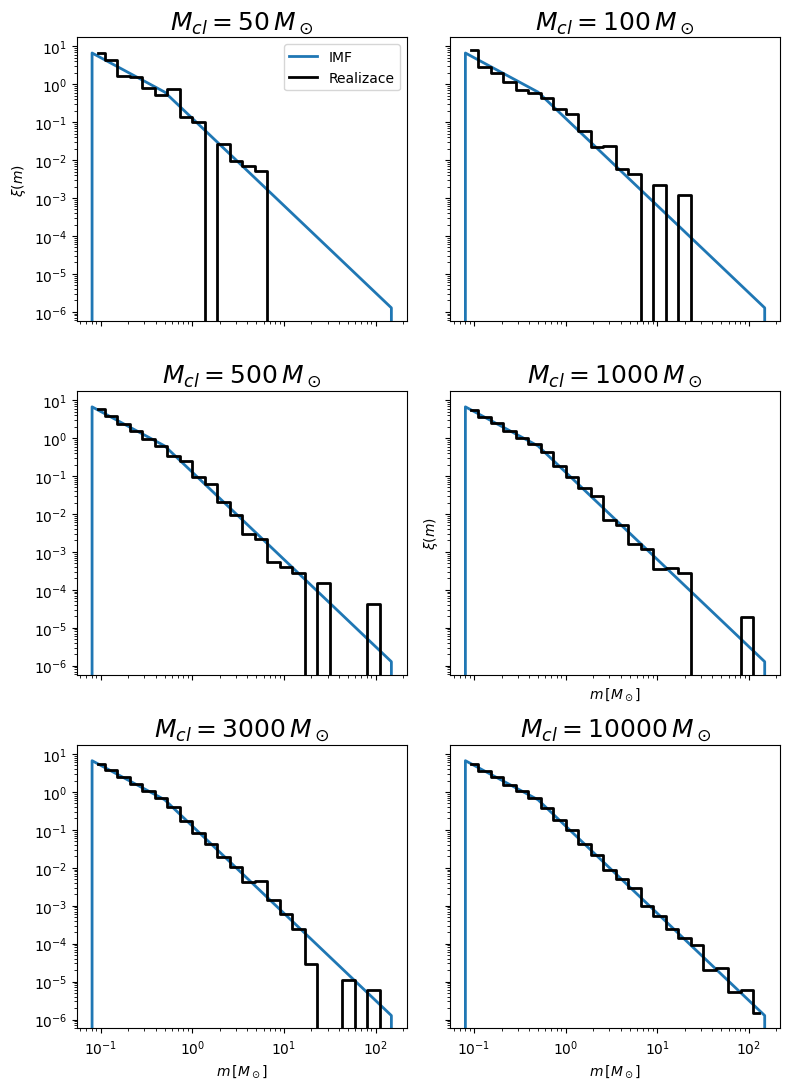

In [77]:
import numpy as np
import matplotlib.pyplot as plt

cluster_masses = [50, 100, 500, 1000, 3000, 10000]

m_grid = np.logspace(np.log10(0.08), np.log10(150), 1000)
A = normalize_imf(custom_imf, 0.08, 150)
xi_theory = A * np.array([custom_imf(m) for m in m_grid])

fig, axes = plt.subplots(3,2, figsize=(8, 11), sharex=True, sharey=True)

axes = axes.flatten()

for i, M in enumerate(cluster_masses):
    ax = axes[i]
    masses = np.array(generate_random_cluster(M))

    bins = np.logspace(np.log10(0.08), np.log10(150), 25)
    hist, edges = np.histogram(masses, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])

    ax.loglog(m_grid, xi_theory, label="IMF", linewidth=2)

    ax.loglog(
        centers,
        hist,
        drawstyle='steps-mid',
        linewidth=2,
        label="Realizace",
        color="black"
    )
    ax.set_title(fr"$M_{{cl}} = {M}\,M_\odot$", fontsize = 18)


for ax in axes[-3:]:
    ax.set_xlabel(r"$m\,[M_\odot]$")

for ax in axes[::3]:
    ax.set_ylabel(r"$\xi(m)$")

axes[0].legend()
plt.tight_layout()
plt.show()

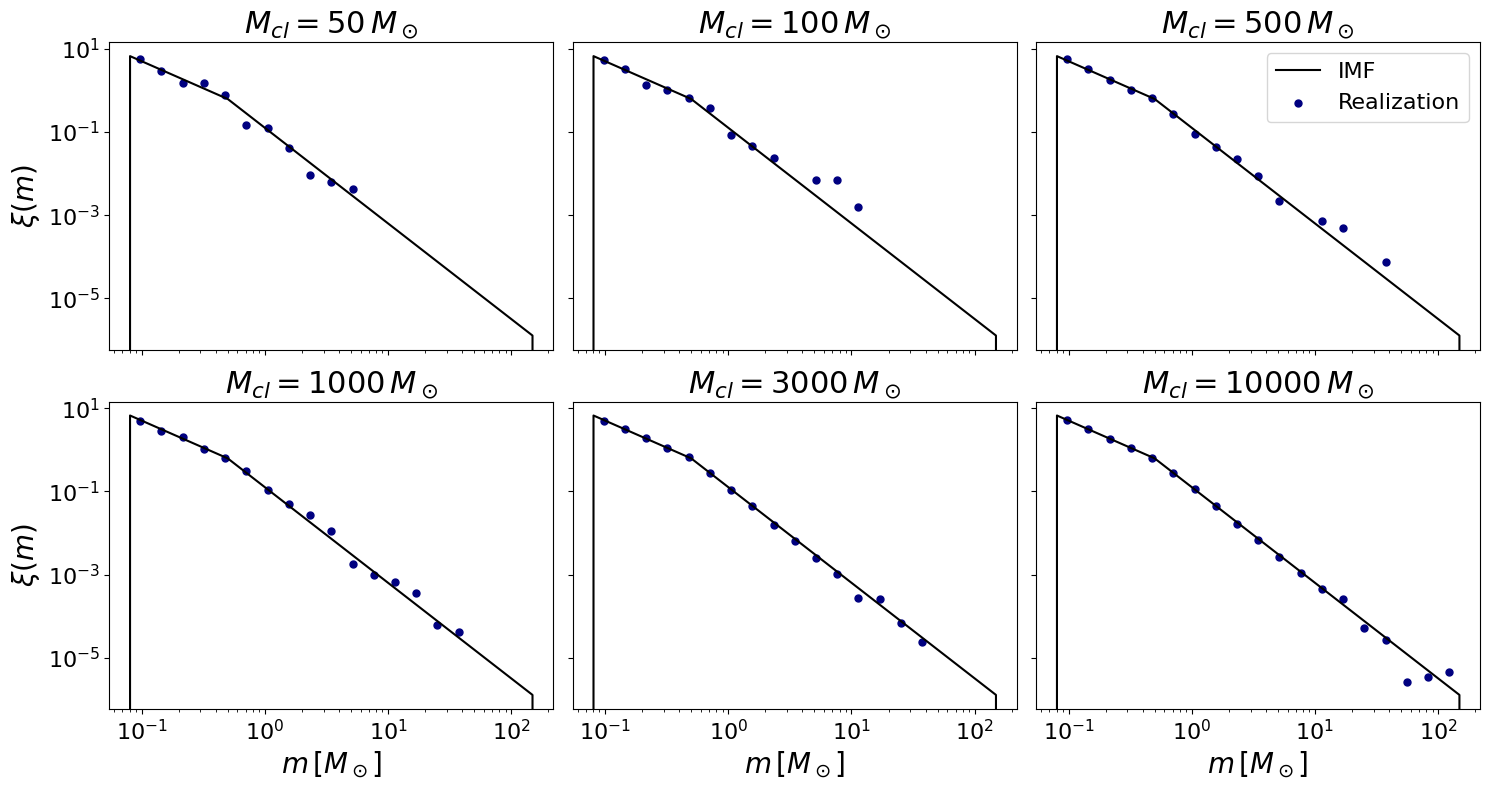

In [49]:
import numpy as np
import matplotlib.pyplot as plt

cluster_masses = [50, 100, 500, 1000, 3000, 10000]

m_grid = np.logspace(np.log10(0.08), np.log10(150), 1000)
A = normalize_imf(custom_imf, 0.08, 150)
xi_theory = A * np.array([custom_imf(m) for m in m_grid])

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

axes = axes.flatten()

for i, M in enumerate(cluster_masses):
    ax = axes[i]

    masses = np.array(generate_random_cluster(M))

    bins = np.logspace(np.log10(0.08), np.log10(150), 20)
    hist, edges = np.histogram(masses, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])

    ax.loglog(m_grid, xi_theory, label="IMF", linewidth=1.5, color="black")
    ax.scatter(centers, hist, s=25, label="Realization", color = "navy")
    ax.tick_params(axis="both", labelsize=16)
    ax.set_title(fr"$M_{{cl}} = {M}\,M_\odot$", fontsize = 22)

for ax in axes[-3:]:
    ax.set_xlabel(r"$m\,[M_\odot]$", fontsize = 20)

for ax in axes[::3]:
    ax.set_ylabel(r"$\xi(m)$", fontsize = 20)

axes[2].legend(fontsize = 16)

plt.tight_layout()
plt.show()

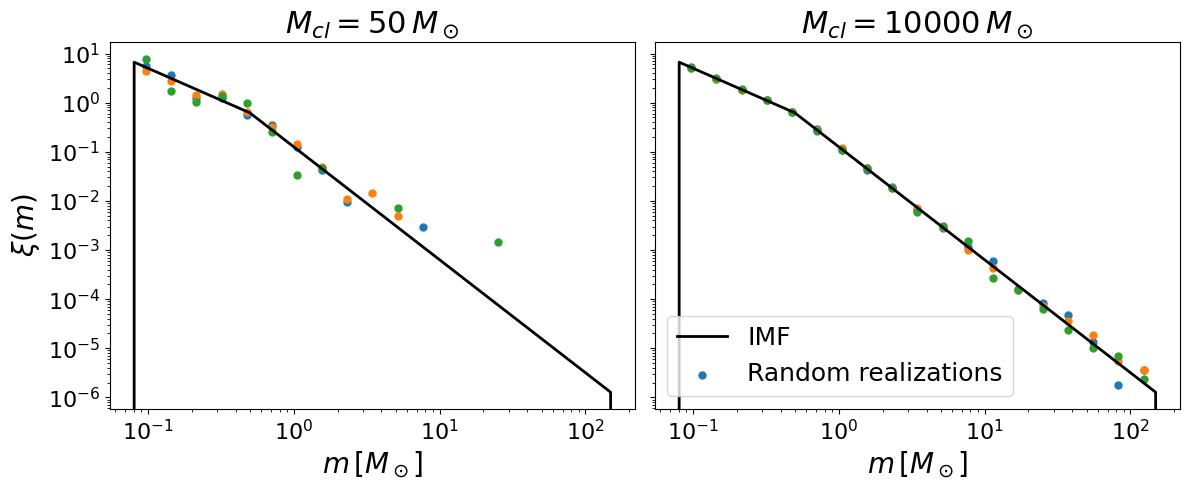

In [31]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

cluster_masses = [50, 10000]

m_grid = np.logspace(np.log10(0.08), np.log10(150), 1000)
A = normalize_imf(custom_imf, 0.08, 150)
xi_theory = A * np.array([custom_imf(m) for m in m_grid])

bins = np.logspace(np.log10(0.08), np.log10(150), 20)

for ax, M in zip(axes, cluster_masses):

    ax.loglog(m_grid, xi_theory, color='black', linewidth=2, label="IMF")

    for i in range(3):
        masses = np.array(generate_random_cluster(M))

        hist, edges = np.histogram(masses, bins=bins, density=True)
        centers = np.sqrt(edges[:-1] * edges[1:])

        ax.scatter(
            centers,
            hist,
            s = 25,
            label="Random realizations" if i == 0 else "_nolegend_"
        )

    ax.set_title(fr"$M_{{cl}} = {M}\,M_\odot$", fontsize = 22)
    ax.tick_params(axis="both", labelsize=16)

axes[0].set_ylabel(r"$\xi(m)$", fontsize = 20)
for ax in axes:
    ax.set_xlabel(r"$m\,[M_\odot]$", fontsize = 20)
axes[1].legend(fontsize = 18)
plt.tight_layout()
plt.show()

In [50]:
from Kroupa_IMF import custom_imf
from My_project.Thesis.Simulated_clusters_ran import generate_random_cluster


In [51]:
import numpy as np
import matplotlib.pyplot as plt

def theoretical_cdf(imf_func, m_min=0.08, m_max=150, n_grid=20000):
    m_grid = np.logspace(np.log10(m_min), np.log10(m_max), n_grid)
    xi = np.array([imf_func(m) for m in m_grid])

    cdf = np.zeros_like(m_grid)
    cdf[1:] = np.cumsum(0.5 * (xi[1:] + xi[:-1]) * (m_grid[1:] - m_grid[:-1]))
    cdf /= cdf[-1]

    return m_grid, cdf

def empirical_cdf(samples):
    x = np.sort(samples)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y

def ks_distance_to_imf(samples, imf_func, m_min=0.08, m_max=150):
    m_grid, cdf_theory = theoretical_cdf(imf_func, m_min, m_max)

    x_emp, y_emp = empirical_cdf(samples)

    y_theory = np.interp(x_emp, m_grid, cdf_theory)

    D = np.max(np.abs(y_emp - y_theory))
    return D

In [58]:
cluster_masses = [50, 100, 500, 1000, 3000, 10000]
n_realizations = 1000

results = {}

for M in cluster_masses:
    Ds = []
    for _ in range(n_realizations):
        masses = np.array(generate_random_cluster(M))
        D = ks_distance_to_imf(masses, custom_imf)
        Ds.append(D)
    results[M] = np.array(Ds)

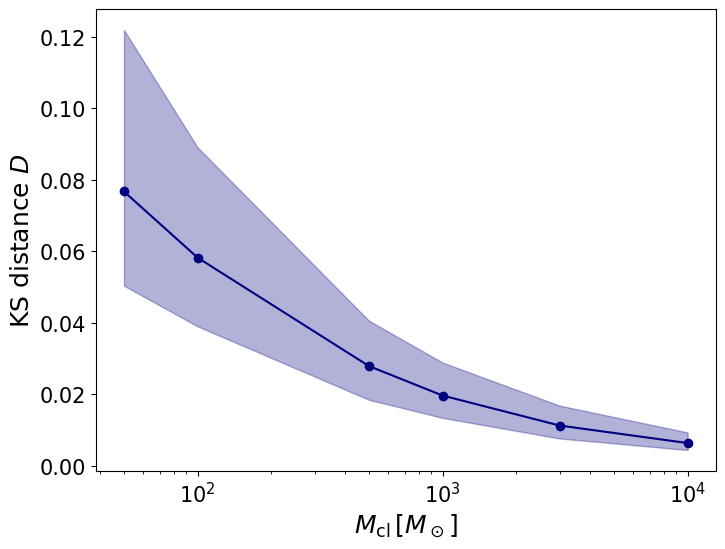

In [61]:
medians = [np.median(results[M]) for M in cluster_masses]
p16 = [np.percentile(results[M], 10) for M in cluster_masses]
p84 = [np.percentile(results[M], 90) for M in cluster_masses]

plt.figure(figsize=(8,6))
plt.plot(cluster_masses, medians, marker='o', color="navy")
plt.fill_between(cluster_masses, p16, p84, alpha=0.3, color="navy")

plt.xscale('log')
plt.xlabel(r'$M_{\mathrm{cl}}\,[M_\odot]$', fontsize=18)
plt.ylabel('KS distance $D$', fontsize=18)
plt.tick_params(axis="both", labelsize=15)
#plt.title('Deviation of random realizations from the theoretical IMF')
#plt.grid(True, which='both', ls='--', alpha=0.4)
plt.show()

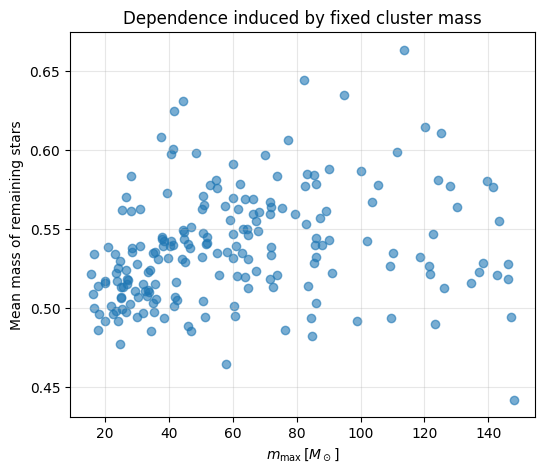

In [47]:
import numpy as np
import matplotlib.pyplot as plt

M = 1000
n_realizations = 200

m_max_list = []
mean_rest_list = []

for _ in range(n_realizations):
    masses = np.array(generate_random_cluster(M))

    m_max = np.max(masses)

    rest = masses[masses != m_max]
    if len(rest) > 0:
        mean_rest = np.mean(rest)

        m_max_list.append(m_max)
        mean_rest_list.append(mean_rest)

plt.figure(figsize=(6,5))
plt.scatter(m_max_list, mean_rest_list, alpha=0.6)

plt.xlabel(r"$m_{\max}\,[M_\odot]$")
plt.ylabel("Mean mass of remaining stars")
plt.title(r"Dependence induced by fixed cluster mass")

plt.grid(True, alpha=0.3)
plt.show()

In [196]:
M_list = random_df["realized_mass"]
mmax_list = random_df["m_max"]

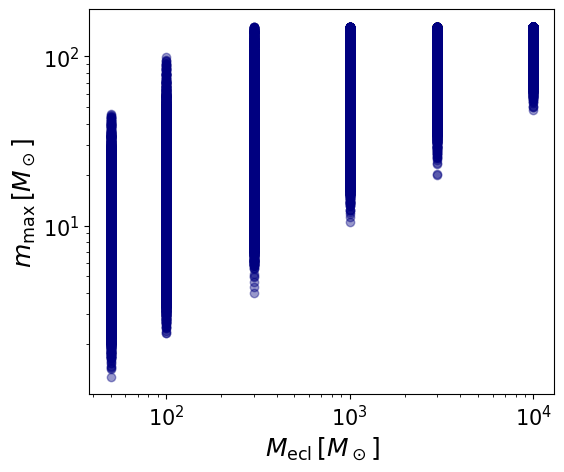

In [197]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

plt.scatter(M_list, mmax_list, alpha=0.4, color="navy")

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r"$M_{\mathrm{ecl}}\,[M_\odot]$", fontsize = 18)
plt.ylabel(r"$m_{\max}\,[M_\odot]$", fontsize = 18)
plt.tick_params(axis='both', which='major', labelsize=15)

plt.show()

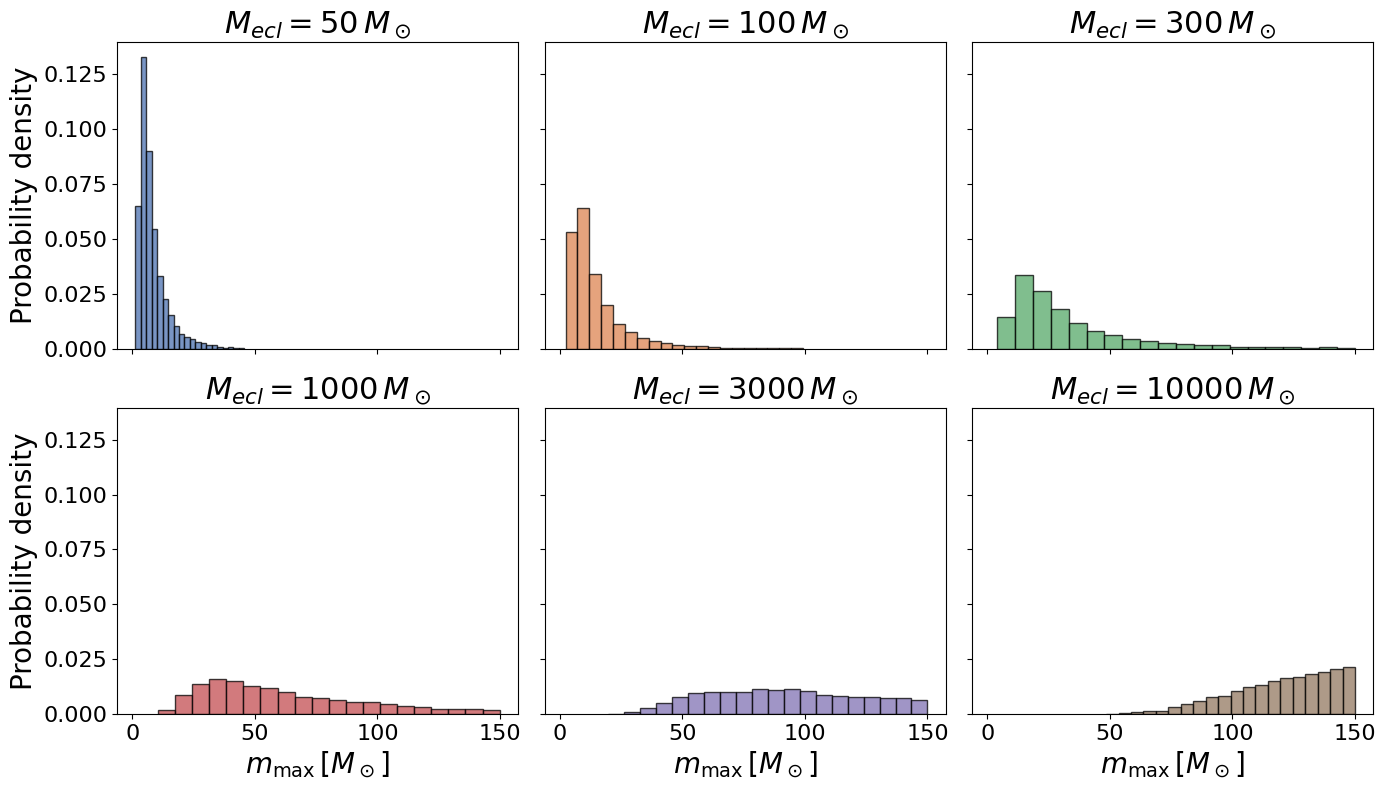

In [13]:
import matplotlib.pyplot as plt

selected_masses = [50, 100, 300, 1000, 3000, 10000]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()

for ax, M, color in zip(axes, selected_masses, colors):
    subset = random_df[random_df["target_mass"] == M]["m_max"]

    ax.hist(
        subset,
        bins=20,
        density=True,
        alpha=0.75,
        color=color,
        edgecolor="black"
    )

    ax.set_title(rf"$M_{{ecl}} = {M}\,M_\odot$", fontsize = 22)
    ax.tick_params(axis="both", labelsize=16)
for ax in axes[3:]:
    ax.set_xlabel(r"$m_{\max}\,[M_\odot]$", fontsize = 20)

for ax in axes[::3]:
    ax.set_ylabel("Probability density", fontsize = 20)

plt.tight_layout()
plt.show()

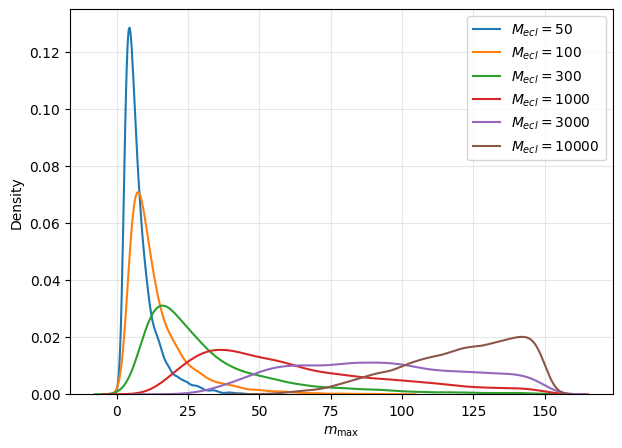

In [202]:
import seaborn as sns

plt.figure(figsize=(7,5))

for M in [50, 100, 300, 1000, 3000, 10000]:
    subset = random_df[np.isclose(random_df["target_mass"], M)]["m_max"]

    if len(subset) > 0:
        sns.kdeplot(subset, label=f"$M_{{ecl}}={M}$")

plt.xlabel(r"$m_{\max}$")
plt.ylabel("Density")

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [203]:
threshold = 20

for M in [50, 100, 300, 1000, 3000, 10000]:
    subset = random_df[np.isclose(random_df["target_mass"], M)]["m_max"]

    prob = np.sum(subset > threshold) / len(subset)

    print(f"M_ecl = {M}: P(m_max > {threshold}) = {prob:.3f}")

M_ecl = 50: P(m_max > 20) = 0.055
M_ecl = 100: P(m_max > 20) = 0.201
M_ecl = 300: P(m_max > 20) = 0.609
M_ecl = 1000: P(m_max > 20) = 0.970
M_ecl = 3000: P(m_max > 20) = 1.000
M_ecl = 10000: P(m_max > 20) = 1.000


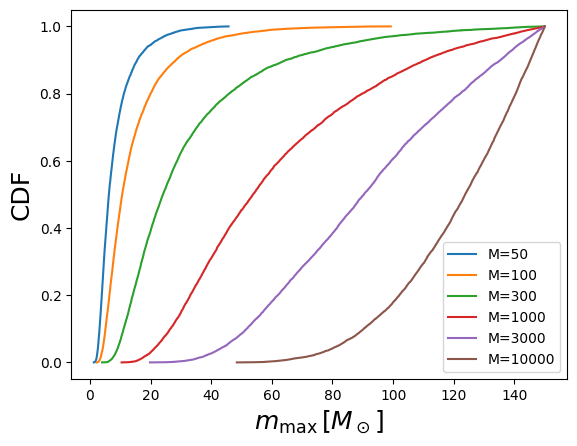

In [15]:
for M in [50, 100, 300, 1000, 3000, 10000]:
    subset = np.sort(random_df[np.isclose(random_df["target_mass"], M)]["m_max"])

    cdf = np.arange(len(subset)) / len(subset)

    plt.plot(subset, cdf, label=f"M={M}")

plt.xlabel(r"$m_{\max}\,[M_\odot]$", fontsize = 18)
plt.ylabel("CDF", fontsize = 18)

plt.legend()

plt.show()

In [25]:
for M in [50, 100, 300, 1000, 3000, 10000]:
    subset = random_df[np.isclose(random_df["target_mass"], M)]["m_max"]

    p16 = np.percentile(subset, 10)
    p50 = np.percentile(subset, 50)
    p84 = np.percentile(subset, 90)

    print(f"M={M}: {p16:.1f}, {p50:.1f}, {p84:.1f}")

M=50: 3.2, 6.7, 16.7
M=100: 4.7, 10.0, 24.2
M=300: 12.0, 22.9, 75.6
M=1000: 27.1, 42.9, 115.8
M=3000: 51.8, 87.1, 136.7
M=10000: 97.4, 129.9, 148.2


M_cl = 50 |
M_cl = 50
With constraint:    rho = -0.751, p = 0.000e+00
Without constraint: rho = 0.204, p = 7.686e-95


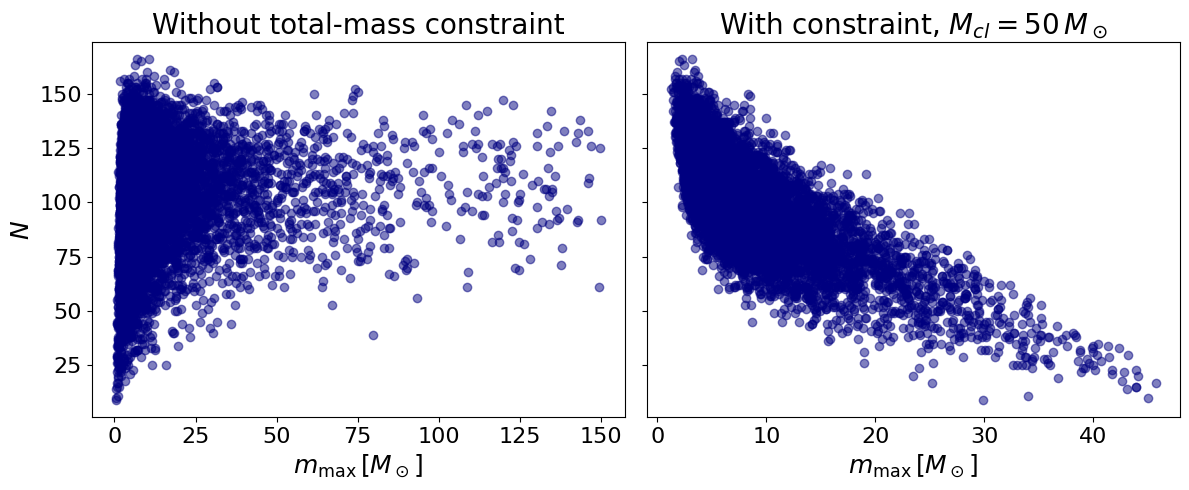

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Helper function used only for the unconstrained comparison.
# It samples the expected maximum stellar mass for a fixed N from the Kroupa IMF.
# This is not the main fixed-Mcl random sampling algorithm used to generate the clusters.
def fast_kroupa_quantile(u):
    m_min, m_mid, m_max = 0.08, 0.5, 150.0
    a1, a2 = 1.3, 2.3
    c1, c2 = 2.0, 1.0

    i1 = c1 * (m_mid**(1-a1) - m_min**(1-a1)) / (1-a1)
    i2 = c2 * (m_max**(1-a2) - m_mid**(1-a2)) / (1-a2)
    p_sep = i1 / (i1 + i2)

    masses = np.where(u < p_sep,
        ( (u/p_sep) * (m_mid**(1-a1) - m_min**(1-a1)) + m_min**(1-a1) )**(1/(1-a1)),
        ( ((u-p_sep)/(1-p_sep)) * (m_max**(1-a2) - m_mid**(1-a2)) + m_mid**(1-a2) )**(1/(1-a2))
    )
    return masses

M_target = 50
df = random_df[np.isclose(random_df["target_mass"], M_target)].copy()

N_constrained = df["n_stars"].to_numpy()
mmax_constrained = df["m_max"].to_numpy()

u = np.random.random(len(N_constrained))
mmax_free = fast_kroupa_quantile(u**(1/N_constrained))

rho_c, p_c = spearmanr(mmax_constrained, N_constrained)
rho_f, p_f = spearmanr(mmax_free, N_constrained)

print(f"M_cl = {M_target} |")

print(f"M_cl = {M_target}")
print(f"With constraint:    rho = {rho_c:.3f}, p = {p_c:.3e}")
print(f"Without constraint: rho = {rho_f:.3f}, p = {p_f:.3e}")

# graph
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].scatter(mmax_free, N_constrained, alpha=0.5, color="navy")
axes[0].set_xlabel(r"$m_{\max}\,[M_\odot]$", fontsize=18)
axes[0].set_ylabel(r"$N$", fontsize=18)
axes[0].set_title("Without total-mass constraint", fontsize=20)

axes[1].scatter(mmax_constrained, N_constrained, alpha=0.5, color="navy")
axes[1].set_xlabel(r"$m_{\max}\,[M_\odot]$", fontsize=18)
axes[1].set_title(fr"With constraint, $M_{{cl}}={M_target}\,M_\odot$", fontsize=20)

for ax in axes:
    ax.tick_params(axis='both', which='major', labelsize=16)

plt.tight_layout()
plt.show()

M_cl = 1000 |
M_cl = 1000
With constraint:    rho = -0.671, p = 0.000e+00
Without constraint: rho = 0.082, p = 2.157e-16


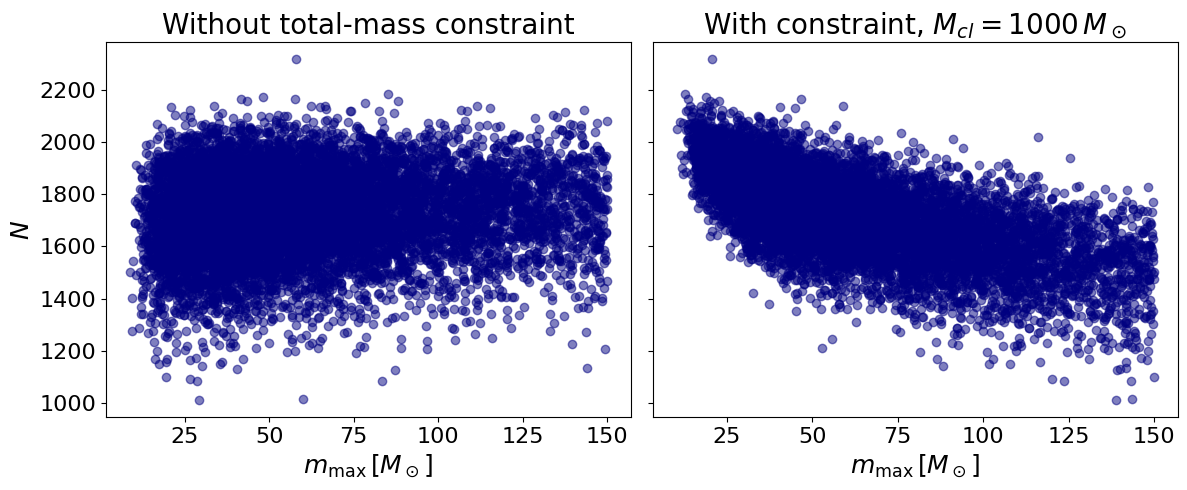

In [68]:
M_target = 1000
df = random_df[np.isclose(random_df["target_mass"], M_target)].copy()

N_constrained = df["n_stars"].to_numpy()
mmax_constrained = df["m_max"].to_numpy()

u = np.random.random(len(N_constrained))
mmax_free = fast_kroupa_quantile(u ** (1 / N_constrained))

rho_c, p_c = spearmanr(mmax_constrained, N_constrained)
rho_f, p_f = spearmanr(mmax_free, N_constrained)

print(f"M_cl = {M_target} |")

print(f"M_cl = {M_target}")
print(f"With constraint:    rho = {rho_c:.3f}, p = {p_c:.3e}")
print(f"Without constraint: rho = {rho_f:.3f}, p = {p_f:.3e}")

# graph
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].scatter(mmax_free, N_constrained, alpha=0.5, color="navy")
axes[0].set_xlabel(r"$m_{\max}\,[M_\odot]$", fontsize=18)
axes[0].set_ylabel(r"$N$", fontsize=18)
axes[0].set_title("Without total-mass constraint", fontsize=20)

axes[1].scatter(mmax_constrained, N_constrained, alpha=0.5, color="navy")
axes[1].set_xlabel(r"$m_{\max}\,[M_\odot]$", fontsize=18)
axes[1].set_title(fr"With constraint, $M_{{cl}}={M_target}\,M_\odot$", fontsize=20)

for ax in axes:
    ax.tick_params(axis='both', which='major', labelsize=16)

plt.tight_layout()
plt.show()

M_cl = 10000 |
M_cl = 10000
With constraint:    rho = -0.340, p = 4.306e-269
Without constraint: rho = 0.021, p = 3.325e-02


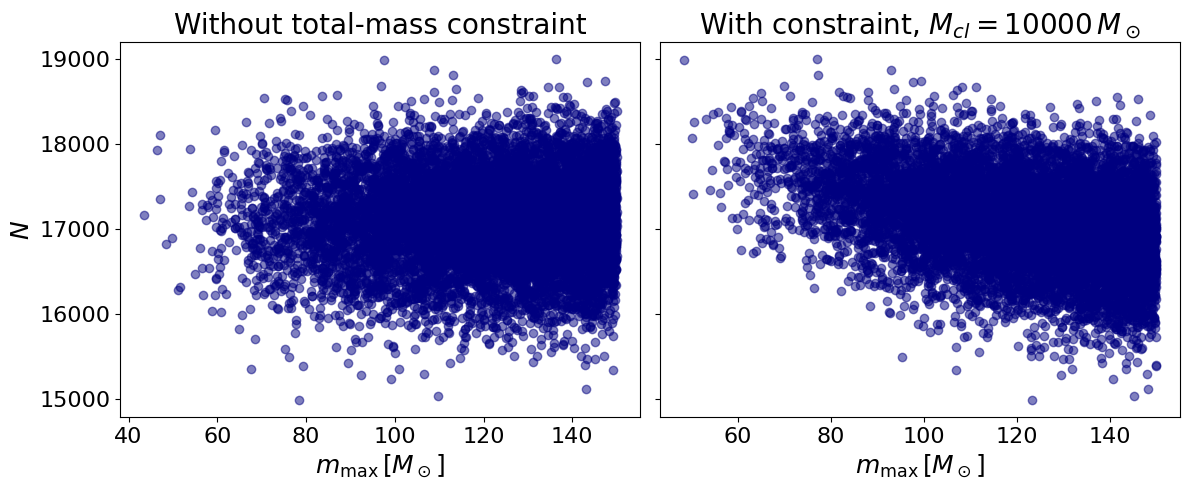

In [69]:
M_target = 10000
df = random_df[np.isclose(random_df["target_mass"], M_target)].copy()

N_constrained = df["n_stars"].to_numpy()
mmax_constrained = df["m_max"].to_numpy()

u = np.random.random(len(N_constrained))
mmax_free = fast_kroupa_quantile(u ** (1 / N_constrained))

rho_c, p_c = spearmanr(mmax_constrained, N_constrained)
rho_f, p_f = spearmanr(mmax_free, N_constrained)

print(f"M_cl = {M_target} |")

print(f"M_cl = {M_target}")
print(f"With constraint:    rho = {rho_c:.3f}, p = {p_c:.3e}")
print(f"Without constraint: rho = {rho_f:.3f}, p = {p_f:.3e}")

# graph
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

axes[0].scatter(mmax_free, N_constrained, alpha=0.5, color="navy")
axes[0].set_xlabel(r"$m_{\max}\,[M_\odot]$", fontsize=18)
axes[0].set_ylabel(r"$N$", fontsize=18)
axes[0].set_title("Without total-mass constraint", fontsize=20)

axes[1].scatter(mmax_constrained, N_constrained, alpha=0.5, color="navy")
axes[1].set_xlabel(r"$m_{\max}\,[M_\odot]$", fontsize=18)
axes[1].set_title(fr"With constraint, $M_{{cl}}={M_target}\,M_\odot$", fontsize=20)

for ax in axes:
    ax.tick_params(axis='both', which='major', labelsize=16)

plt.tight_layout()
plt.show()